This notebook covers a general EDA of the data used, an overview of the methods chosen for the anomaly detection task, their efficacy and some considerations on these. It is to be considered a birdseye view of the work conducted. The validated results are not found here but in the "experiments" section. This notebook can be useed to play around with the methods and the dataset. The average execution time is 30min.

In [1]:
#utils
import pandas as pd
import numpy as np
import contextlib
import os
import warnings

#visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve


warnings.filterwarnings("ignore")

#it's important that eager execution is enabled
#it comes as a default setting in tensorflow 2.0
if tf.executing_eagerly():
    print("Eager execution is enabled.")
else:
    print("Eager execution is not enabled.")


Eager execution is enabled.


In [2]:
df = pd.read_csv('SimData.csv')
df = df.head(200)

In [3]:
#this gives us the duimension of the dataset we're working with.
df.shape

(200, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   isghost  200 non-null    int64  
 1   chi2     200 non-null    float64
 2   nb_hits  200 non-null    int64  
 3   qop      200 non-null    float64
 4   tx       200 non-null    float64
 5   ty       200 non-null    float64
 6   x        200 non-null    float64
 7   y        200 non-null    float64
 8   z        200 non-null    float64
dtypes: float64(7), int64(2)
memory usage: 14.2 KB


In [5]:
df.isghost.describe()

count    200.000000
mean       0.070000
std        0.255787
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: isghost, dtype: float64

# Visualize all the data points where ghost=1 and any feature has an outlier value

qop stands for "charge-to-over-momentum" ratio, is a measure of the electric charge of a particle relative to its momentum

In [6]:
target_feature = "isghost"
columns = df.drop(columns=target_feature).columns
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
train_normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

In [7]:
#also instantiate a dataframe to carry all the features
#and a second one to instead contain the target variable
def get_normal_data(df):
    df = df.sample(frac=1)
    features = df.drop([target_feature], axis=1)
    label = df[target_feature]

    #the stratify parameter here is set to be "isghost" meaning that the 
    #proportions of ghost and normal tracks in both train and test datasets
    #will be kept the same...
    x_train, x_test, y_train, y_test = train_test_split(
        features, label, test_size=0.2, stratify=label
    )

    #remember that at least for the autoencoders we're gonna use just the 
    #normal instances during the training phase so we have to filter those in x_train
    train_index = y_train[y_train == 0].index
    train_normal_data = x_train.loc[train_index]

    return train_normal_data, x_train, y_train, x_test, y_test

In [8]:
train_normal_data, x_train, y_train, x_test, y_test = get_normal_data(df)

This is to show the distribution of the features before standardization.

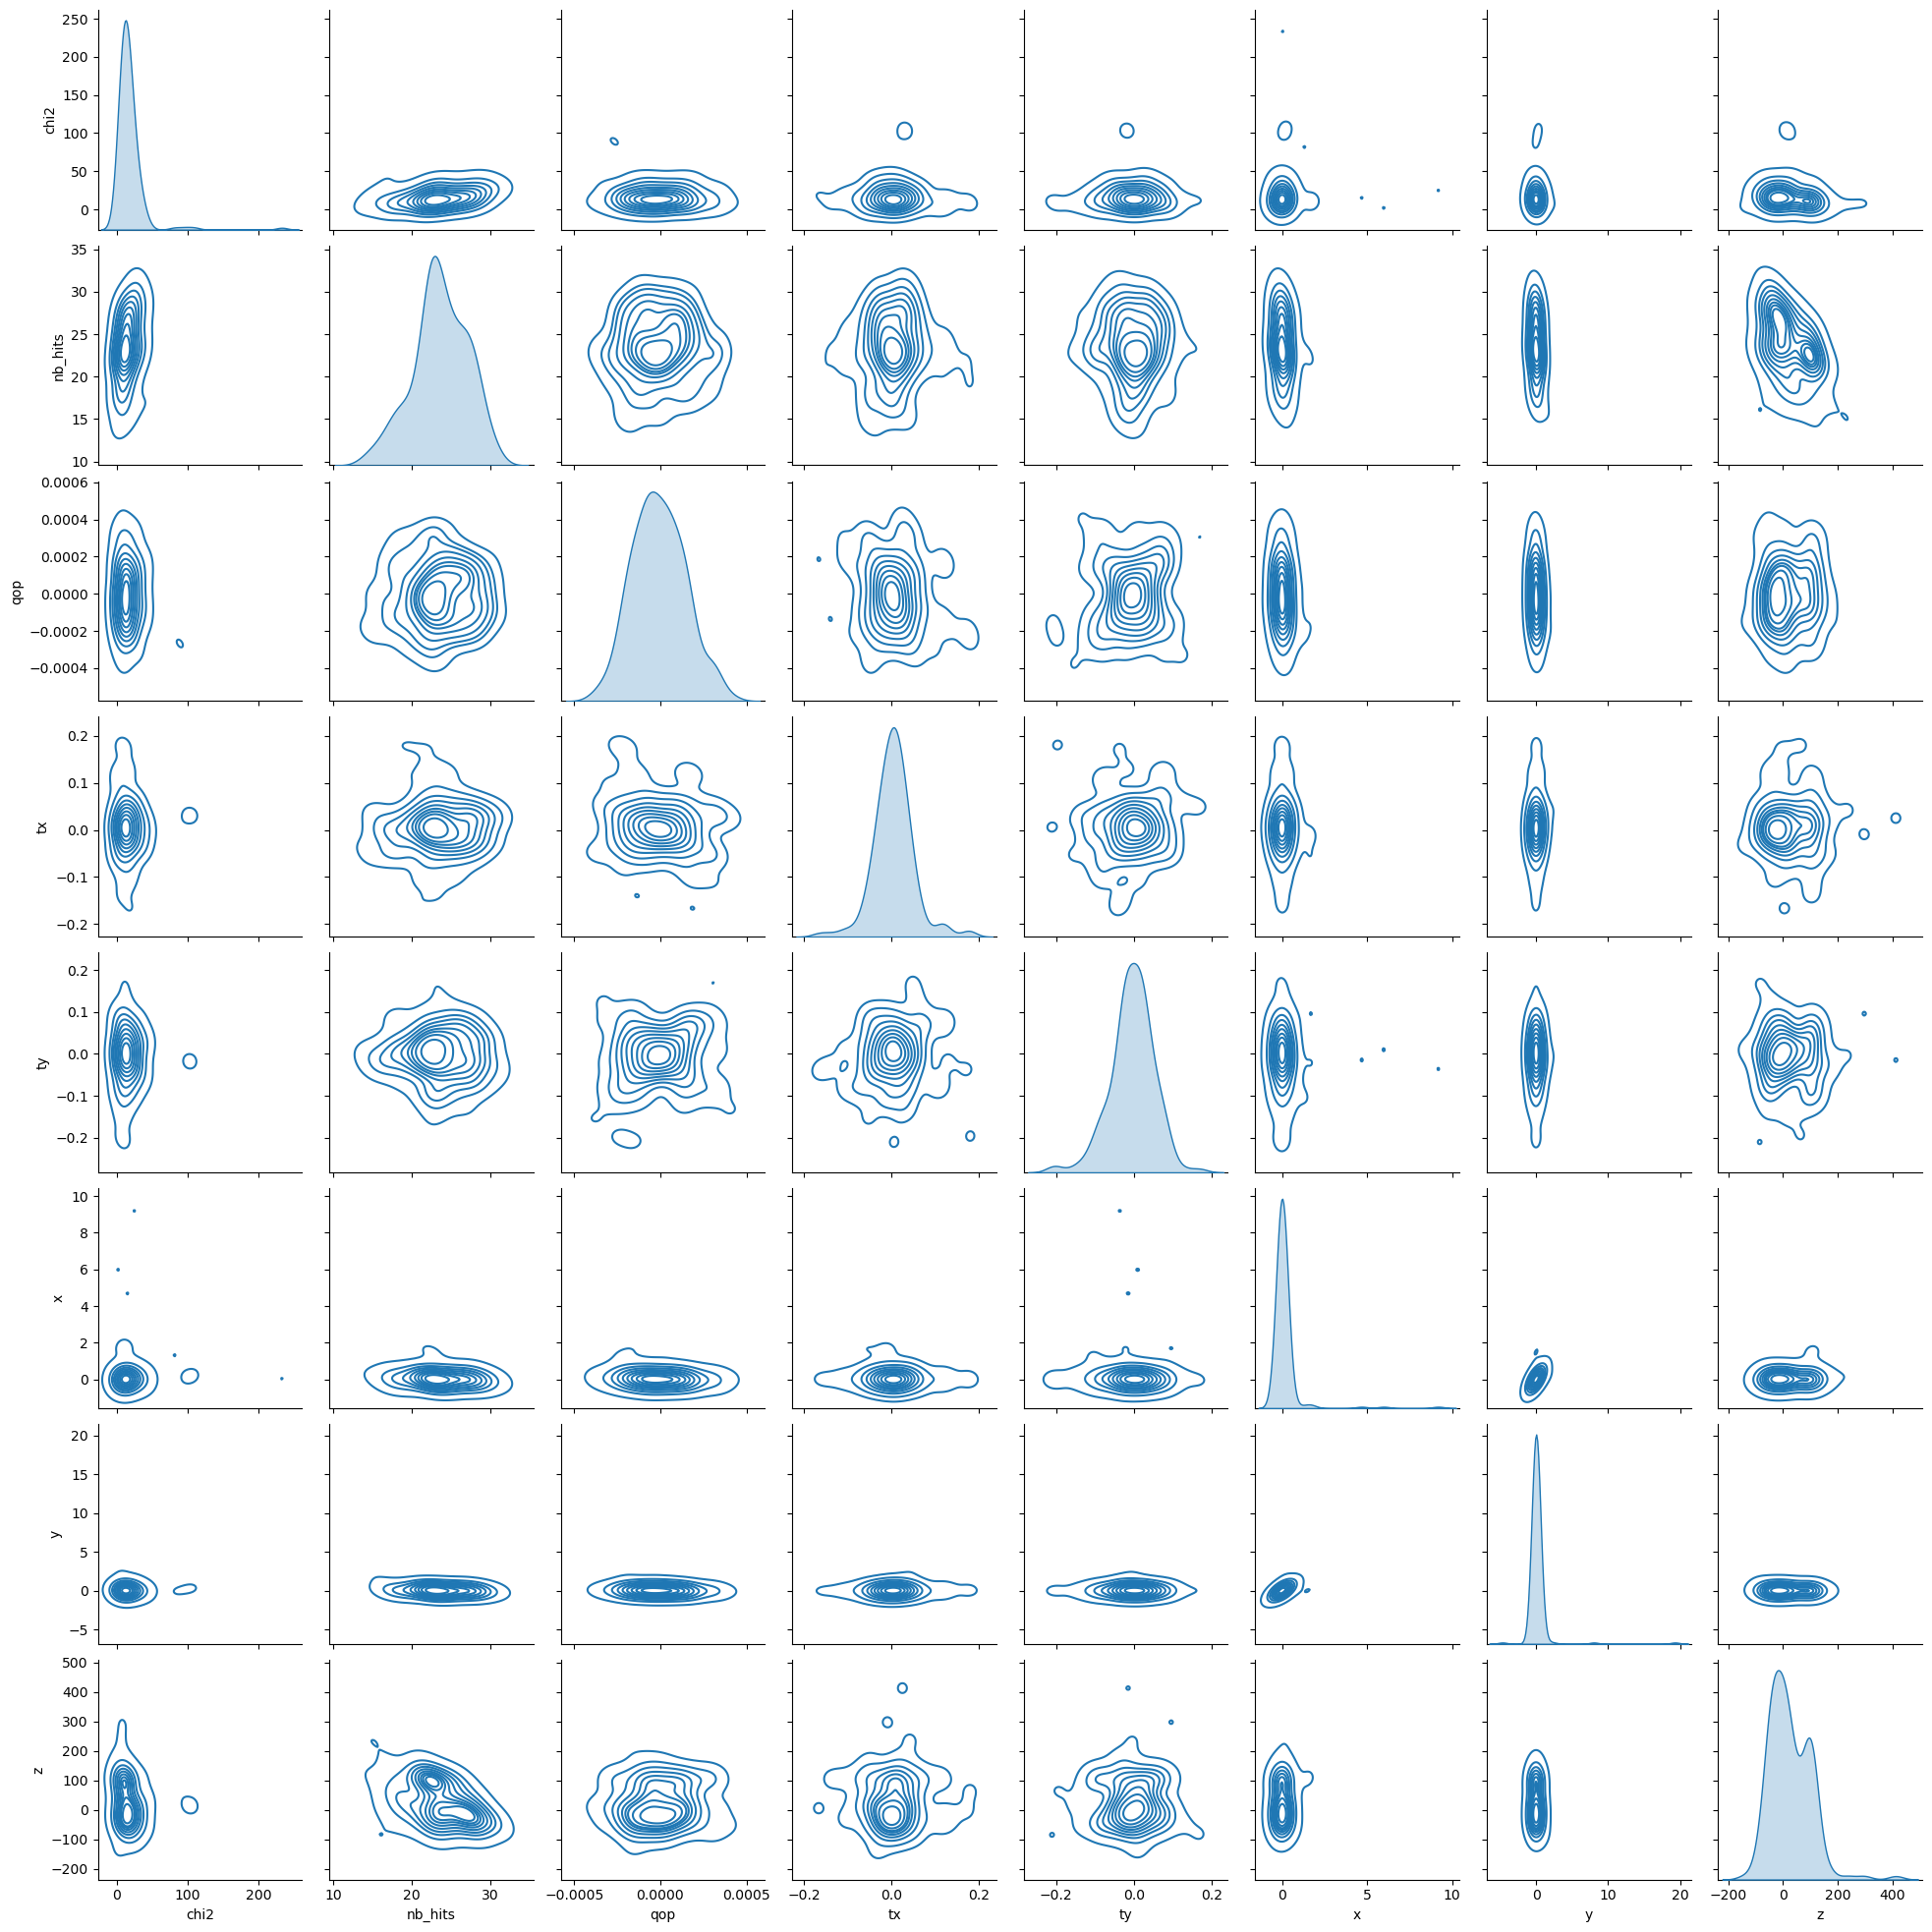

In [9]:
sns.pairplot(x_train, kind='kde')


In [10]:
def standardize_normalize(train_x, normal_train_data, test_data):
    #here I need to rescale the data as the featurea have different ranges 


    #Don't forget that testing data points represent real-world data.
    #Feature normalization (or data standardization) of the explanatory (or predictor) variables
    #is a technique used to center and normalise the data by subtracting the mean and dividing by the variance.
    #If you take the mean and variance of the whole dataset you'll be introducing future information
    #into the training explanatory variables (i.e. the mean and variance).

    #Therefore, you should perform feature normalisation over the training data.
    #Then perform normalisation on testing instances as well, but this time using the mean and variance
    #of training explanatory variables. In this way, we can test and evaluate
    #whether our model can generalize well to new, unseen data points.

    #creating a scaler and decing which columns to process
    normal_train_data = (normal_train_data - normal_train_data.mean()) / normal_train_data.std()
    train_x  =  (train_x - train_x.mean()) / train_x.std()
    test_data = (test_data - normal_train_data.mean()) / normal_train_data.std()

    #now moving the data to a fixed range of values 
    scaler = MinMaxScaler()

    normal_train_data = scaler.fit_transform(normal_train_data)
    train_x = scaler.fit_transform(train_x)
    test_data = scaler.fit_transform(test_data)

    return train_x, normal_train_data, test_data

In [11]:
x_train, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

The following plot shows the effect of standardization and normalization to the data distribution. As it can be seen while the range has been changed the distribution has not been changed.  

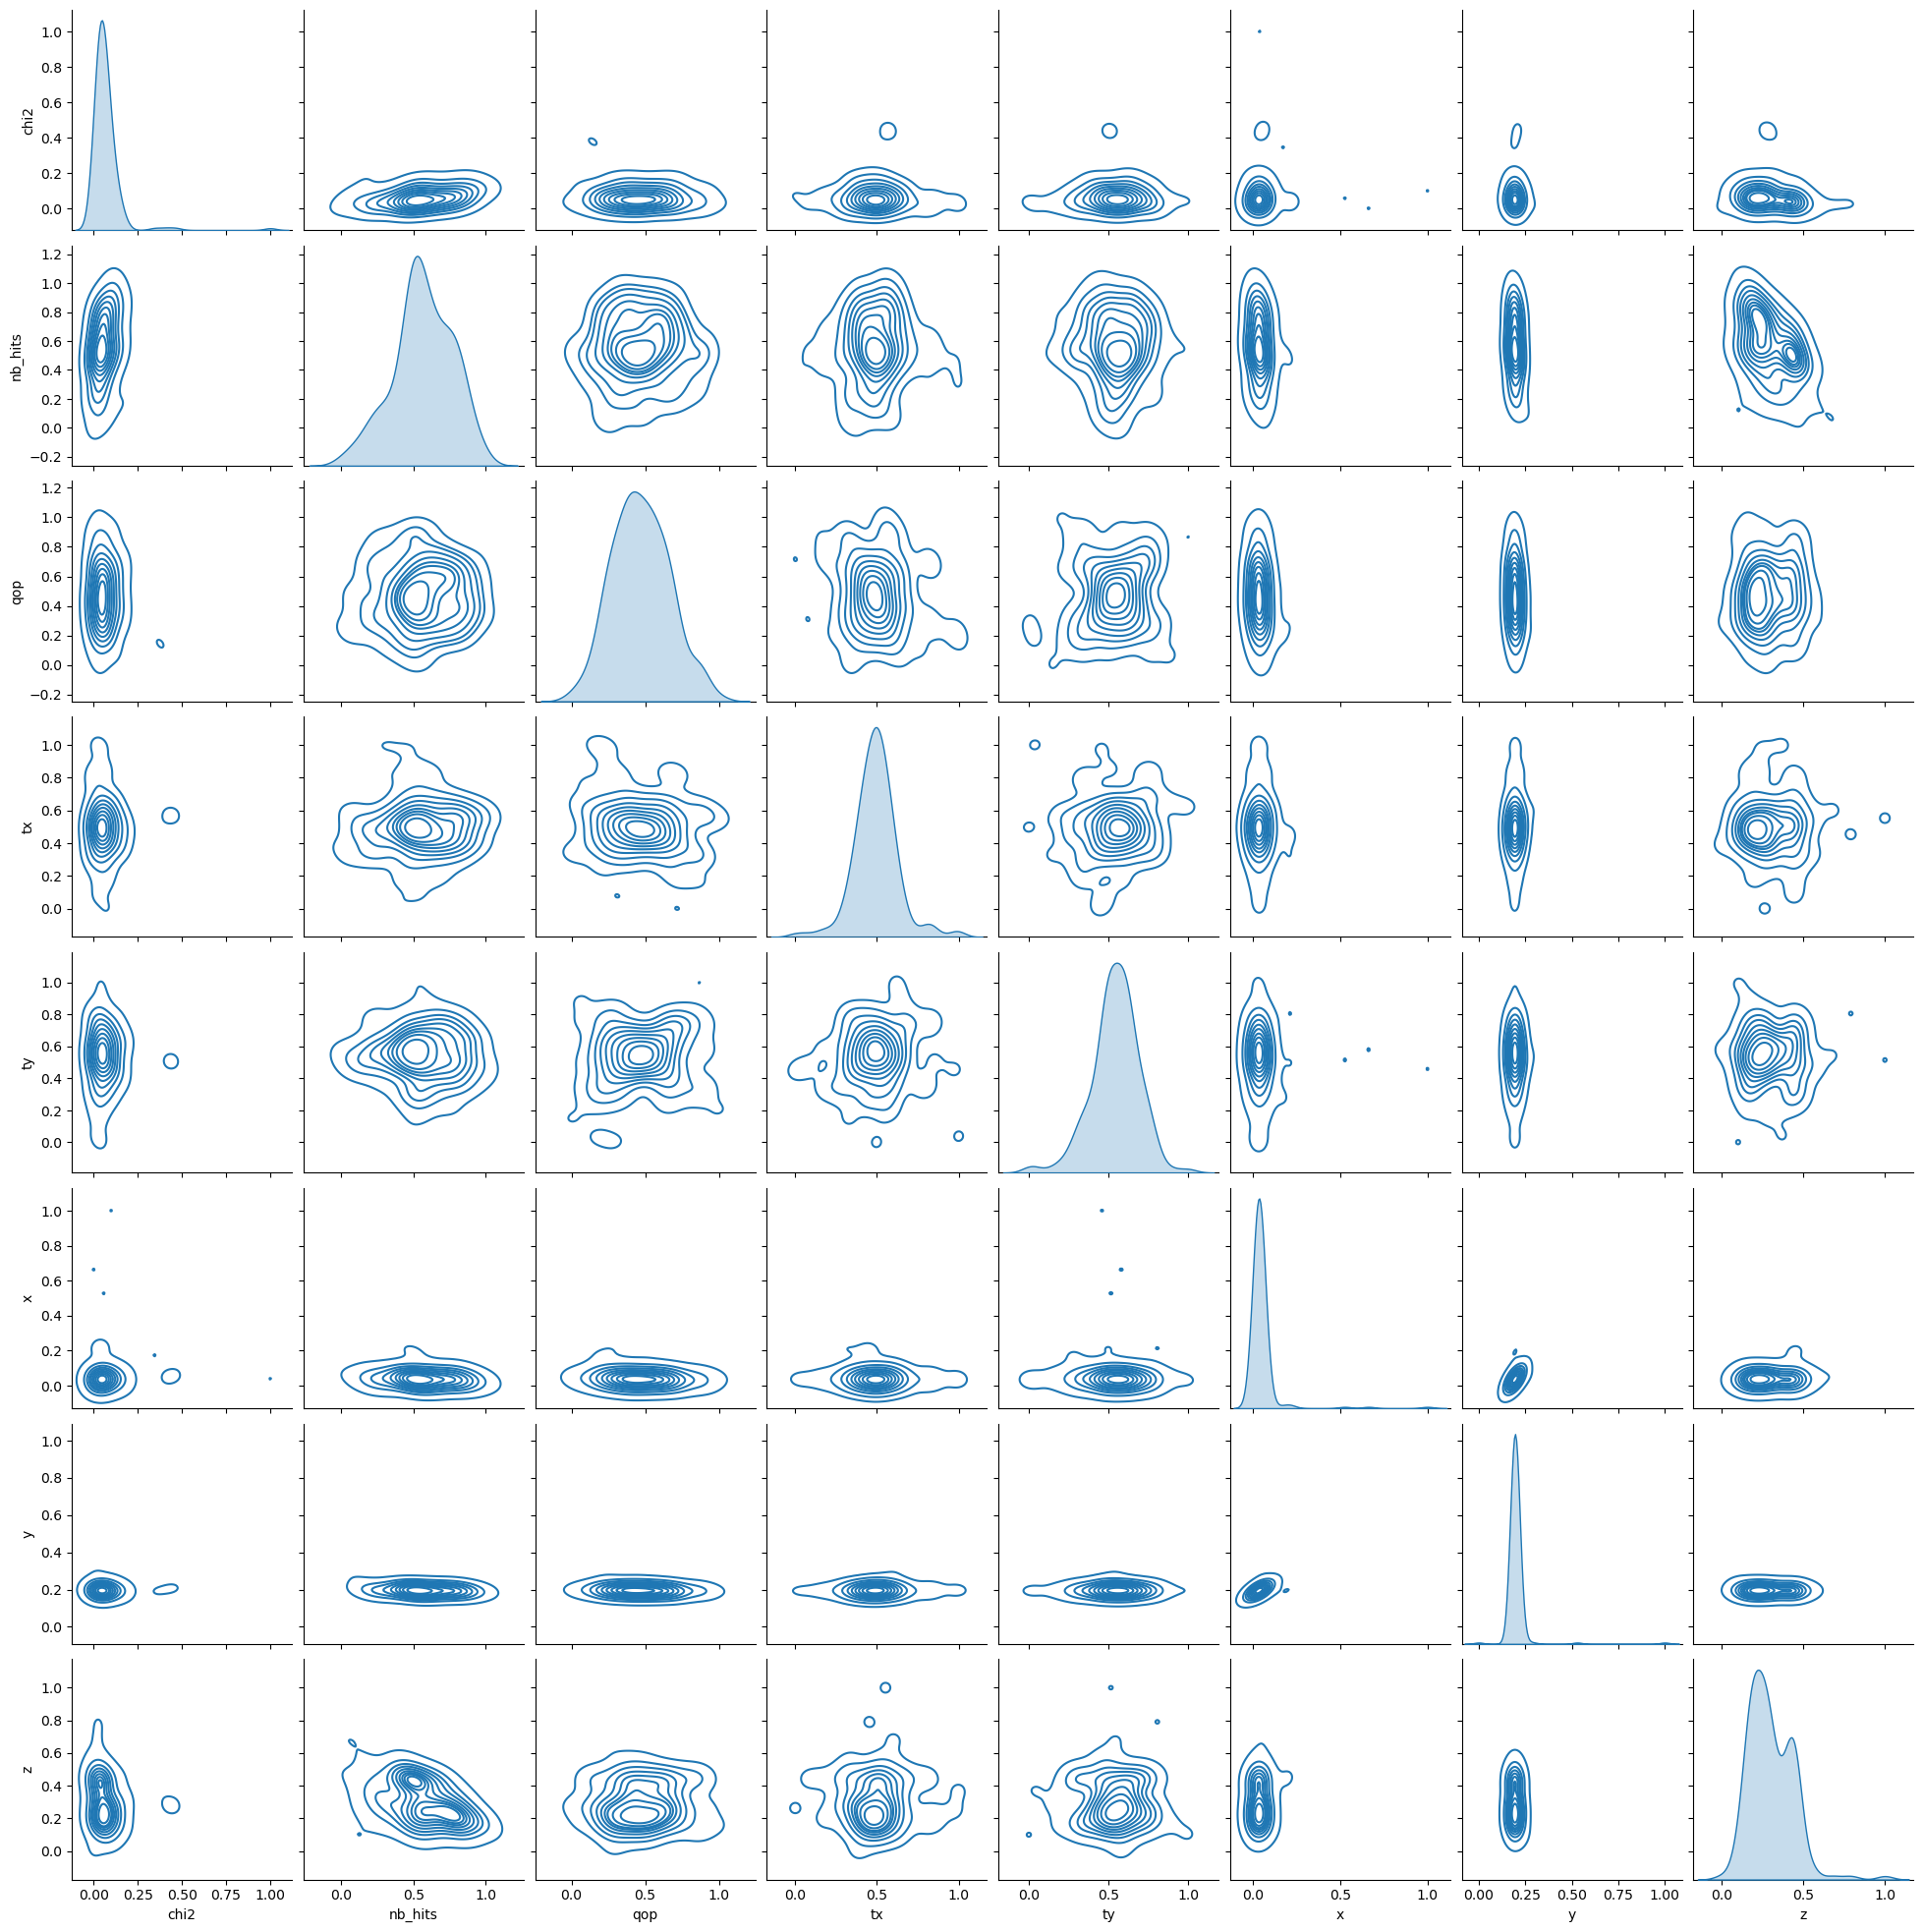

In [12]:
sns.pairplot(pd.DataFrame(x_train, columns=columns), kind='kde')

# Visualization

<Axes: >

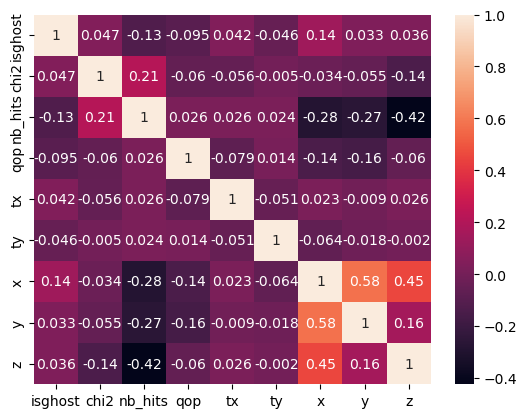

In [13]:
corr = df.corr().round(3)
sns.heatmap(corr, annot=True)

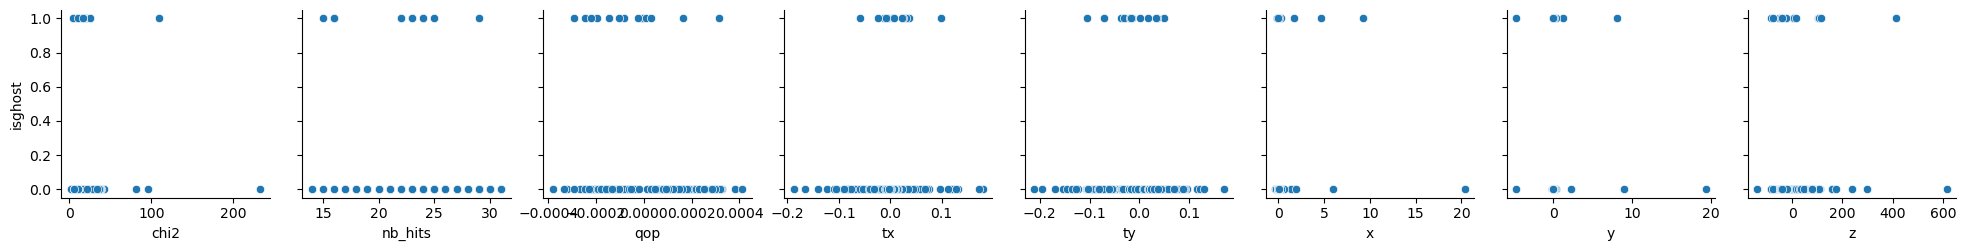

In [14]:
sns.pairplot(data=df, x_vars= df.drop(columns=target_feature).columns, y_vars=[target_feature])

plt.show()

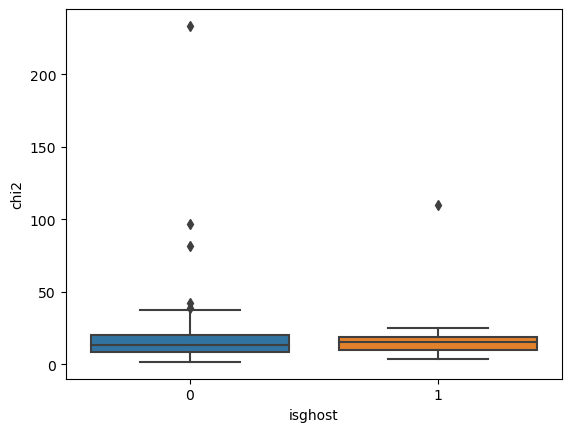

In [15]:
sns.boxplot(x=target_feature, y='chi2', data=df)

plt.show()

# Model Fitting

In [16]:
from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.VariationalAutoencoder import VariationalAutoEncoder


#instantiate the contractive autoencoder
#the input dimension should match with the input features
#instead the latent dimensionis the desired compression rate
#such that higher latent_dim result in lower compression rate and more expressivity
#while instead lower latent dimension leads to less reconstruction quality
# but also less validatinon error (less model complexity)

#The latent space representation captures the most salient features of the input data
#a lower latent_dim may lead to a higher reconstruction error for anomalous inputs,
#setting latent_dim too low may also result in the loss of important information
#latent dimension should start small and then raised until diminishing returns 


#when performing anomaly detection using autoencoders these have to be trained using normal data
#such that the network learns to reproduce those instances, and that we can then perform the 
#detection using a threshold applied on the reconstruction error of any instance
input_dim = train_normal_data.shape[1]
latent_dim = 3
learning_rate = 0.001
epochs = 5

vae = VariationalAutoEncoder(input_dim=input_dim, latent_dim=latent_dim, learning_rate=learning_rate)
vae.build(input_shape=(train_normal_data.shape))
cae = ContractiveAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, lambda_= 0.01, learning_rate=learning_rate)
cae.build(input_shape=(train_normal_data.shape))
ae = Autoencoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
ae.build(input_shape=(train_normal_data.shape))


In [17]:
#start the training of the NN,
#assuming a convex loss function the higher the number of epochs the better the results will be.
#an higher batch size implies that a larger share of the training examples are processed together
#this eventually leads to fatser training and higher generalizion error (model doesn't learn underlying distribution but training data) 
history_cae, training_time_cae = cae.train(train_normal_data, epochs=epochs, batch_size=30)


Step: 0, Train Loss: 0.09862537682056427, Val Loss: 0.09435297548770905
Step: 0, Train Loss: 0.0894123837351799, Val Loss: 0.0836508721113205
Step: 0, Train Loss: 0.06816316395998001, Val Loss: 0.06000695750117302
Step: 0, Train Loss: 0.03170512989163399, Val Loss: 0.031228553503751755
Step: 0, Train Loss: 0.026858557015657425, Val Loss: 0.030039004981517792


In [18]:
history_ae, training_time_ae = ae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)

Epoch 1/5
4/4 [==============================] - 2s 114ms/step - loss: 0.0983 - val_loss: 0.0930
Epoch 2/5
4/4 [==============================] - 0s 17ms/step - loss: 0.0894 - val_loss: 0.0778
Epoch 3/5
4/4 [==============================] - 0s 16ms/step - loss: 0.0635 - val_loss: 0.0399
Epoch 4/5
4/4 [==============================] - 0s 17ms/step - loss: 0.0312 - val_loss: 0.0341
Epoch 5/5
4/4 [==============================] - 0s 17ms/step - loss: 0.0265 - val_loss: 0.0261


In [19]:
history_vae, training_time_vae = vae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)


Epoch 1/5
4/4 [==============================] - 2s 114ms/step - loss: 0.6843 - val_total_loss: 0.0000e+00
Epoch 2/5
4/4 [==============================] - 0s 16ms/step - loss: 0.6356 - val_total_loss: 0.0000e+00
Epoch 3/5
4/4 [==============================] - 0s 28ms/step - loss: 0.5603 - val_total_loss: 0.0000e+00
Epoch 4/5
4/4 [==============================] - 0s 22ms/step - loss: 0.5303 - val_total_loss: 0.0000e+00
Epoch 5/5
4/4 [==============================] - 0s 31ms/step - loss: 0.5240 - val_total_loss: 0.0000e+00


In [20]:
print("Training time AE: " + str(training_time_ae) + "training time CAE: " + str(training_time_cae) + " training time VAE: " + str(training_time_vae)) 

Training time AE: 2.2006747722625732training time CAE: 1.0169081687927246 training time VAE: 2.1085774898529053


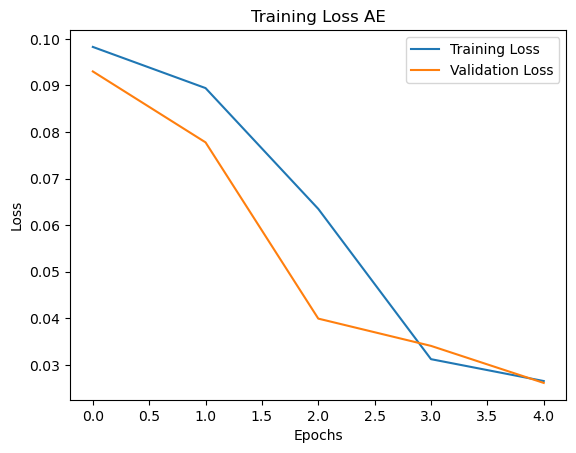

In [21]:
# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_ae.history['loss'], label='Training Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss AE')

# Add legend
plt.legend()

# Display the plot
plt.show()

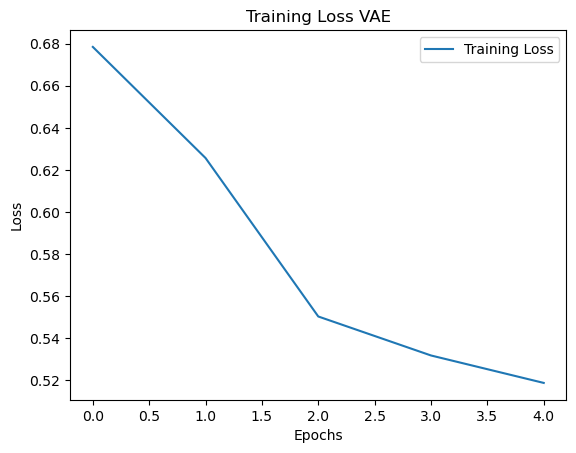

In [22]:
"""

#variational loss training and validation loss
train_losses = [item[0] for item in history_vae]
val_losses = [item[1] for item in history_vae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

"""


# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_vae.history['loss'], label='Training Loss')
#plt.plot(history_vae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss VAE')

# Add legend
plt.legend()

# Display the plot
plt.show()


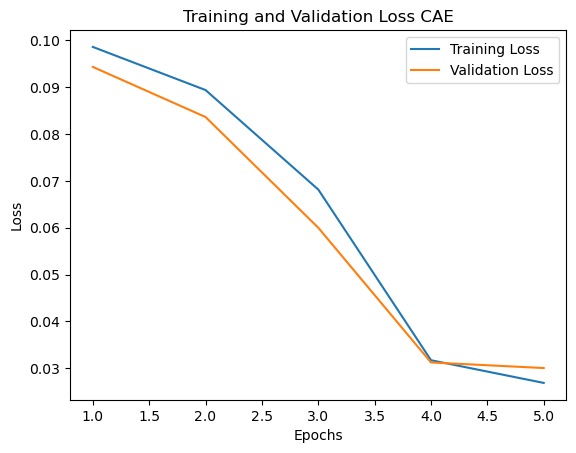

In [23]:
#contractive loss training and validation loss
train_losses = [item[0] for item in history_cae]
val_losses = [item[1] for item in history_cae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

5/5 [==============================] - 0s 6ms/step


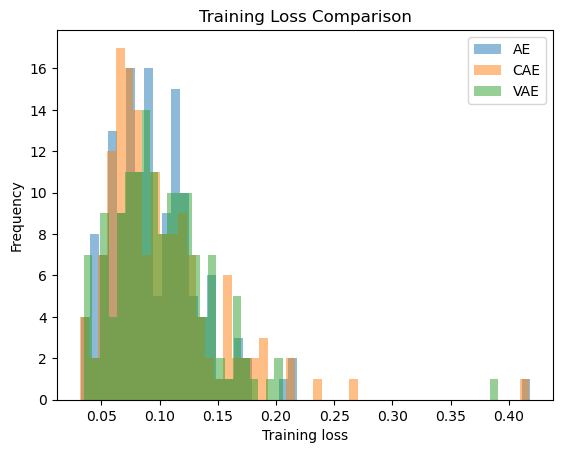

In [24]:
#MAE of the CAE over the number of samples 
cae_train_pred = cae.call(train_normal_data)
cae_mae_loss = np.mean(np.abs(cae_train_pred - train_normal_data), axis=1)

#MAE of the AE over the number of samples 
ae_train_pred = ae.predict(train_normal_data)
ae_mae_loss = np.mean(np.abs(ae_train_pred - train_normal_data), axis=1)

#MAE of the VAE over the number of samples 
vae_train_pred = vae.predict(train_normal_data)
vae_mae_loss = np.mean(np.abs(vae_train_pred - train_normal_data), axis=1)

# Plotting
plt.hist(ae_mae_loss, alpha= 0.5, label='AE', bins=50)
plt.hist(cae_mae_loss, alpha= 0.5, label='CAE', bins=50)
plt.hist(vae_mae_loss, alpha= 0.5, label='VAE', bins=50)

# Add labels and title
plt.xlabel('Training loss')
plt.ylabel('Frequency')
plt.title('Training Loss Comparison')

# Add legend
plt.legend()

# Display the plot
plt.show()

# Setting a threshold
In anomaly detection, a threshold is used to determine whether a sample is normal or anomalous based on its reconstruction error (i.e., the difference between the input and its reconstruction).

The threshold is typically set by selecting a value such that any sample with a reconstruction error above the threshold is classified as an anomaly, while any sample with a reconstruction error below the threshold is classified as normal. To come up with said thrashold we're going to take the mean and standard deviation of the residuals, and cosnidering a number of standard deviations away from the mean we're gonna find a threshold. 
The threshold needs to be set on the reconstruction for the training and not for the test as that would introduce some information on the underlying distribution of the data.

In [25]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    deviations_threshold_ae = ae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_cae = cae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
    deviations_threshold_vae = vae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)

In [26]:
#getting 
predictions_ae = ae.find_anomalies(x_test, deviations_threshold_ae)

#looking at the metrics for anomaly detection so far
ae.classification_metrics(y_test, predictions_ae, printing=True)

2/2 [==============================] - 0s 8ms/step
Accuracy: 0.2750
Precision: 0.0938
Recall: 1.0000
F1-Score: 0.1714
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.22      0.36        37
           1       0.09      1.00      0.17         3

    accuracy                           0.28        40
   macro avg       0.55      0.61      0.26        40
weighted avg       0.93      0.28      0.34        40



In [27]:
#getting the predictions
predictions_cae = cae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
cae.classification_metrics(y_test, predictions_cae, printing=True)

Accuracy: 0.2250
Precision: 0.0882
Recall: 1.0000
F1-Score: 0.1622
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.16      0.28        37
           1       0.09      1.00      0.16         3

    accuracy                           0.23        40
   macro avg       0.54      0.58      0.22        40
weighted avg       0.93      0.23      0.27        40



In [28]:
#getting the predictions
predictions_vae = vae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
vae.classification_metrics(y_test, predictions_vae, printing=True)

2/2 [==============================] - 0s 3ms/step
Accuracy: 0.1750
Precision: 0.0588
Recall: 0.6667
F1-Score: 0.1081
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.14      0.23        37
           1       0.06      0.67      0.11         3

    accuracy                           0.17        40
   macro avg       0.45      0.40      0.17        40
weighted avg       0.78      0.17      0.22        40



# Performance 

Here we're going to take into consideration some metrics, with their relevant visualization, of the models' performance in the anomaly detectino task. 
As first step we're so going to look into the ROC curve, that is a plot of the "False positive rate" against the "True positive rate". The curve therefore aims at 
describing the strength of a classifier, such that the more the curve appriaches the top left corner the strongest the method is. While instead if the curve approaches the 
line y = x, or the corss-section of the plane, the more the classifier approaches a random one. 

In [29]:
def plot_ROC(y_test, predictions, name):

    # find the roc curve for the actual target values and the predictions
    fpr, tpr, _ = roc_curve(y_test, predictions)
    roc_auc = auc(fpr, tpr)

    #finding the Youden's J statistic, it's a metric that describes the power of classifier
    #where 0 is random guesser and 1 is a perfect classifier
    j_statistic = tpr - fpr
    print("the j_statistic is " + str(j_statistic[1]))

    #plotting the roc curve with the best trehsold against the random predictor
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + name)
    plt.legend(loc="lower right")
    plt.show()


the j_statistic is 1.0


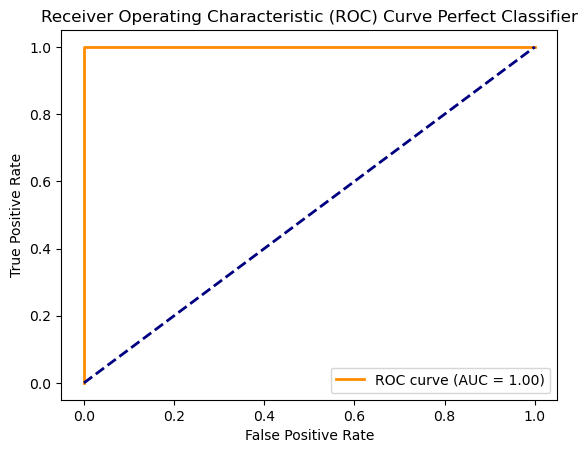

In [30]:
plot_ROC(y_test=y_test, predictions=y_test, name="Perfect Classifier")

the j_statistic is 0.21621621621621623


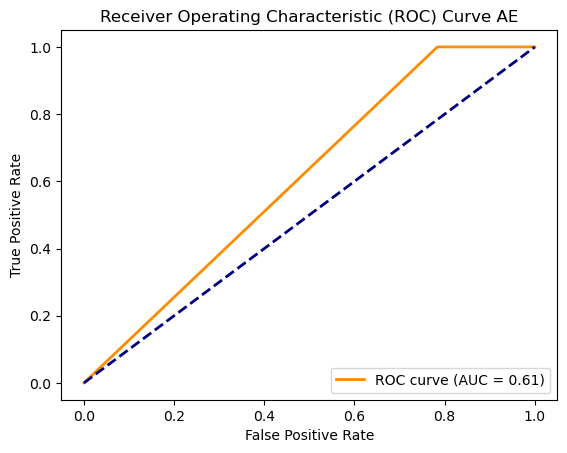

In [31]:
plot_ROC(y_test=y_test, predictions=predictions_ae, name="AE")

the j_statistic is 0.16216216216216217


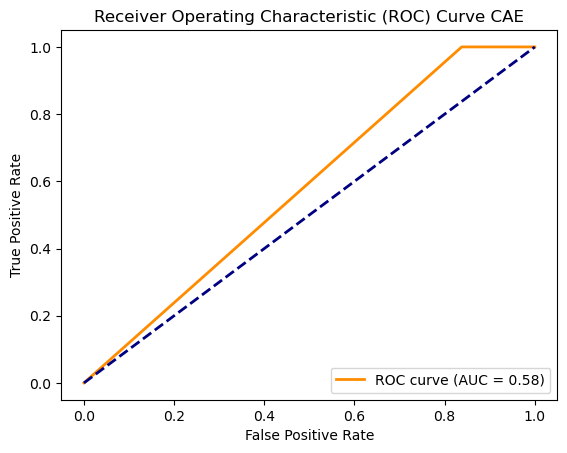

In [32]:
plot_ROC(y_test=y_test, predictions=predictions_cae, name="CAE")

the j_statistic is -0.19819819819819828


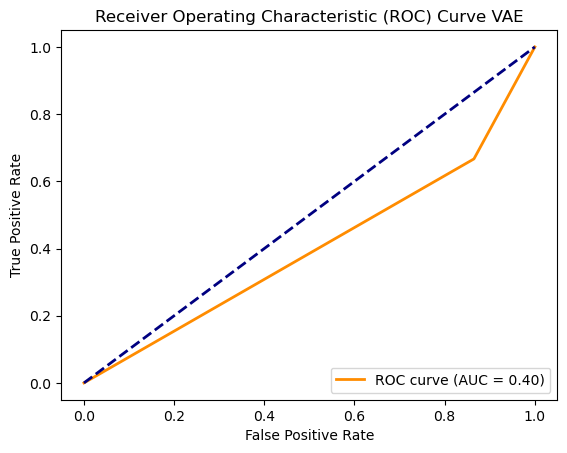

In [33]:
plot_ROC(y_test=y_test, predictions=predictions_vae, name="VAE")

### Precision recall curve

This type of plot is made to better understand the performance of the models, given an high class imbalance. Precision indicates the proportion of correct positive identifications. Recall instead the proportion of actual positives that has been identified correctly. A perfect classifier is a squashed against the top right corner. A no-skill model will instead have a precision equal to the % of the positive class. 

https://analyticsindiamag.com/complete-guide-to-understanding-precision-and-recall-curves/

In [34]:
def pr_curve(y_true, predictions, name):

    precision, recall, _ = precision_recall_curve(y_true, predictions)
    #find the no_skill classifier line
    no_skill_precision = np.sum(y_true) / len(y_true)

    # plot the precision-recall curve
    plt.plot(recall, precision, color="darkorange")
    plt.axhline(y=no_skill_precision, color='navy', linestyle='--', label='No Skill')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve ' + name)
    plt.show()

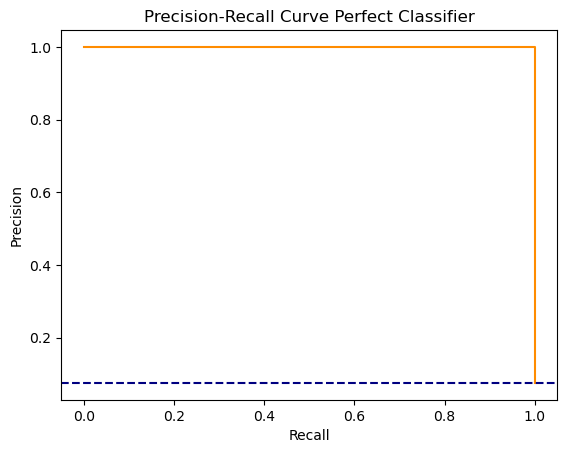

In [35]:
pr_curve(y_true=y_test, predictions=y_test, name="Perfect Classifier")

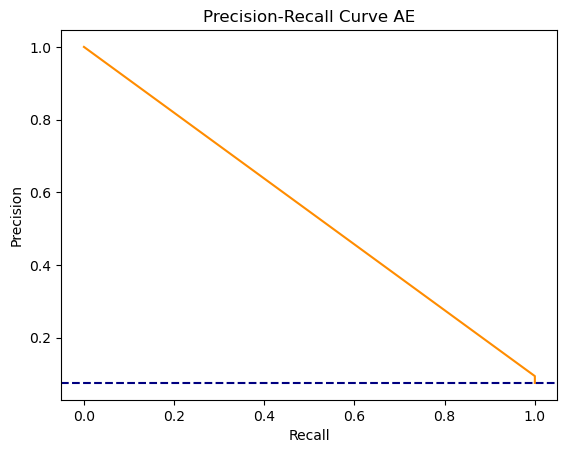

In [36]:
pr_curve(y_test, predictions_ae, name="AE")

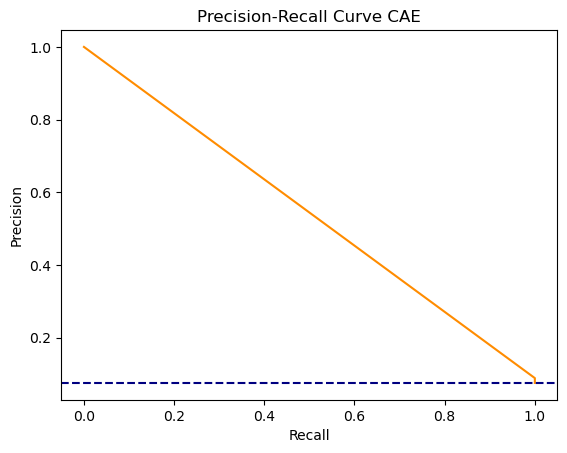

In [37]:
pr_curve(y_test, predictions_cae, name="CAE")

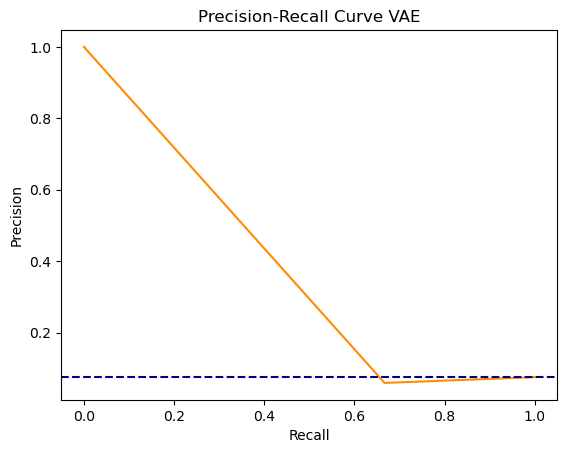

In [38]:
pr_curve(y_test, predictions_vae, name="VAE")

### Latent space plot.

Here we investigate how the ghost and normal samples are separated by the different models in the latent space. Eventually we would like to have the ghost tracks clustered together and so the normal ones. The normal tracks will be shown in green and the ghost tracks in red. 

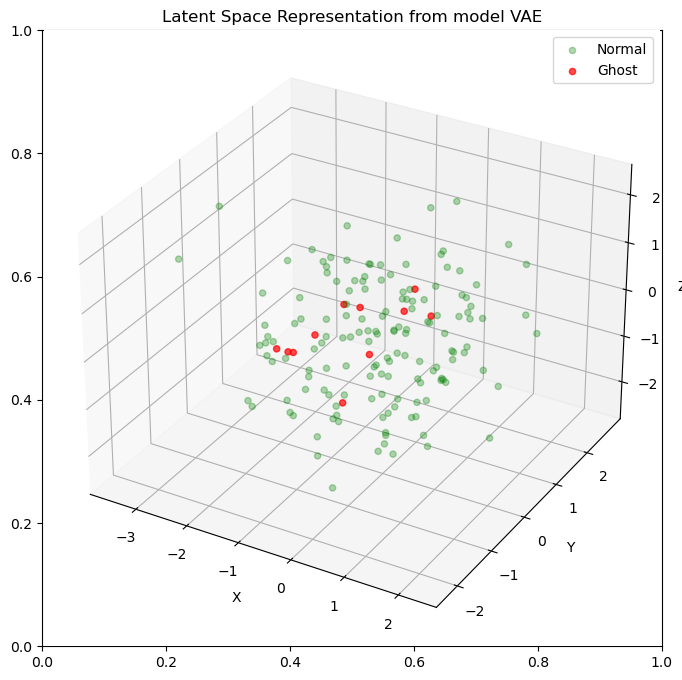

In [39]:
def plot_latent(name, model):
    
    data = tf.convert_to_tensor(x_train)
    latent_representation = model.encode(data)

    #different models have different ways of outputting the encoded data
    if tf.is_tensor(latent_representation):
        latent_representation = latent_representation.numpy()


    #accessing the value coordinates for the encoded data
    X = latent_representation[:,0]
    y = latent_representation[:,1]
    z = latent_representation[:,2]
    
    #plotting the data points in a 3D space
    #the green points correspond to normal instances
    #the red points correspond to the anomlaous data
    fig, ax = plt.subplots(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X[y_train==0], y[y_train==0], z[y_train==0], c='g', alpha=0.3, label='Normal')
    ax.scatter(X[y_train==1], y[y_train==1], z[y_train==1], c='r', alpha=0.7, label='Ghost')

    # labeling
    ax.legend(loc='best')
    ax.set_title('Latent Space Representation from model ' + name)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    # saving & displaying
    #plt.savefig('latent_representation_3d');
    plt.show()

plot_latent("VAE", vae)

5/5 [==============================] - 0s 2ms/step


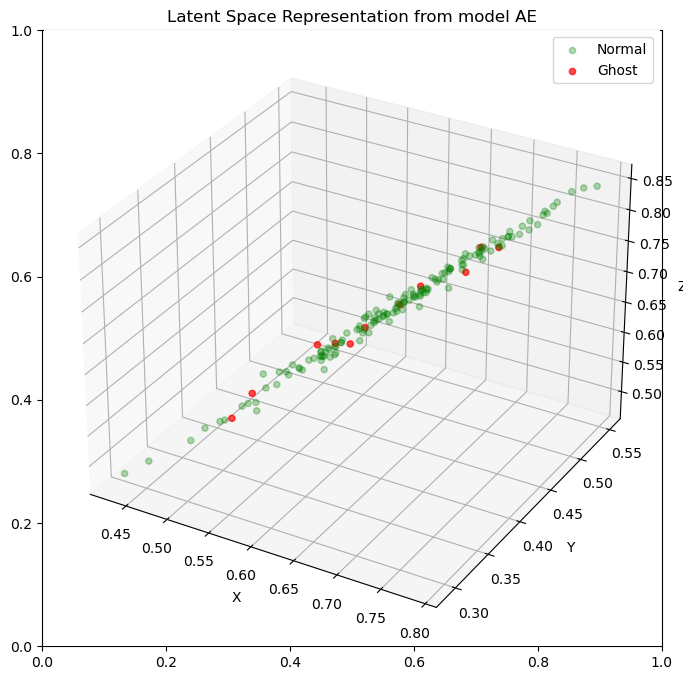

In [40]:
plot_latent("AE", ae)

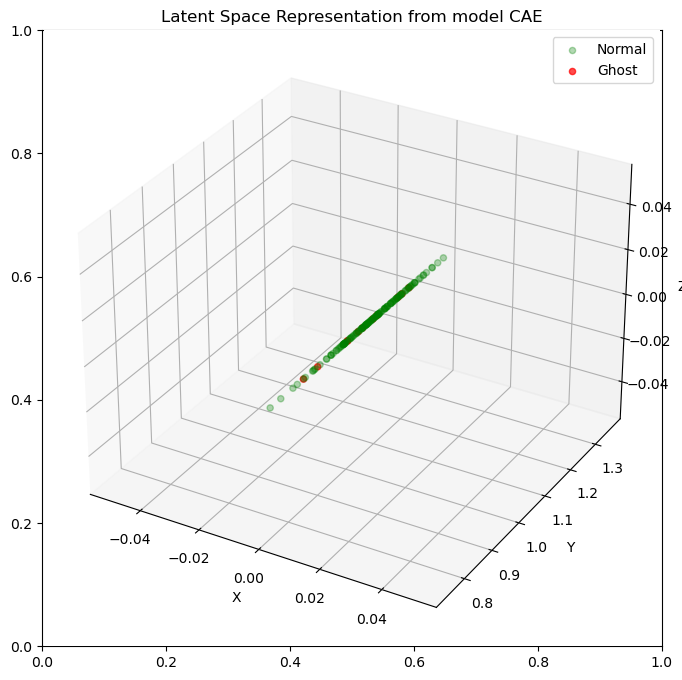

In [41]:
plot_latent("CAE", cae)

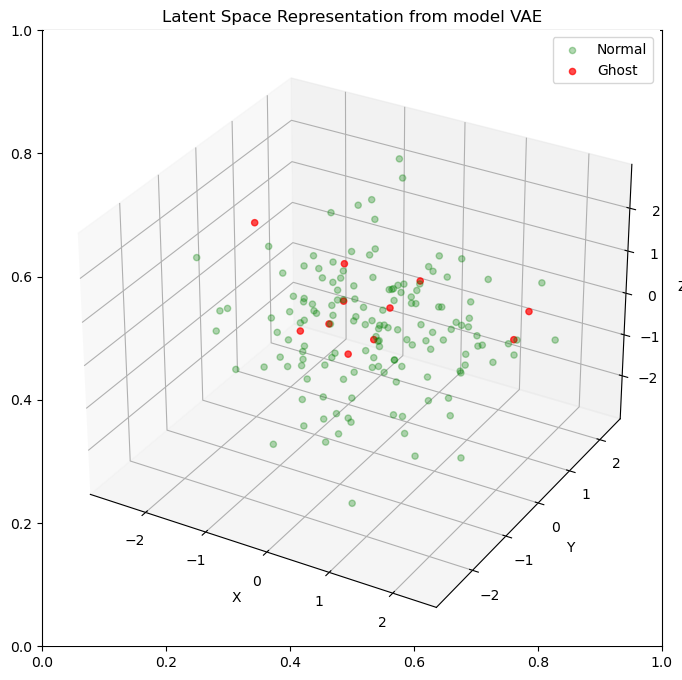

In [42]:
plot_latent("VAE", vae)

### Reconstruction error 

Here I'm plotting the reconstruction error distribution of the different methods so to have a overview of their "strength" and point out eventual discrepancies.

In [43]:
def plot_reconstruction_error(errors): 
    
    normal = errors[y_test==0]
    ghost = errors[y_test==1]

    _, ax = plt.subplots(figsize=(8,8))

    ax.hist(normal, bins=50, density=True, label="Normal", alpha=0.6)
    ax.hist(ghost, bins=50, density=True, label="Ghost", alpha=0.6)
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Reconstruction loss")

    plt.title("(Normalized) Distribution of the Reconstruction Loss")
    
    plt.legend()
    plt.show()

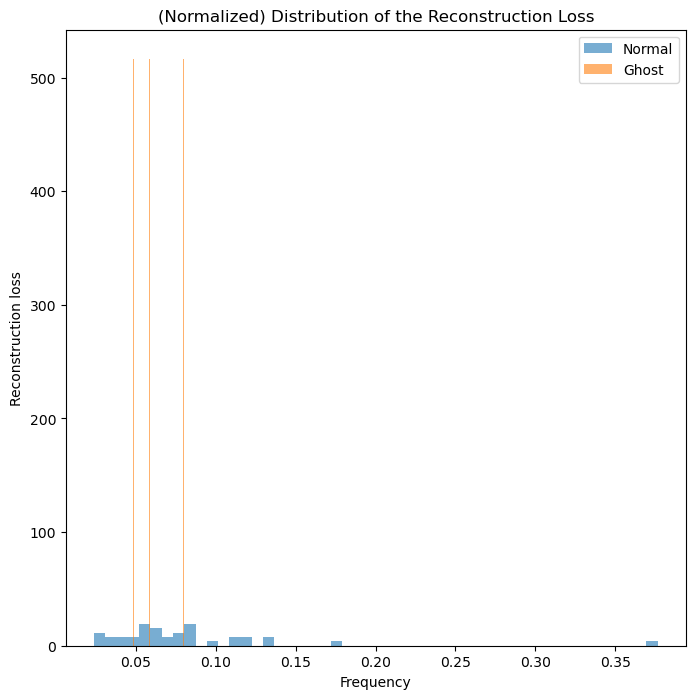

In [44]:
reconstruction_ae = ae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_ae, 2), axis=1)
plot_reconstruction_error(mse)

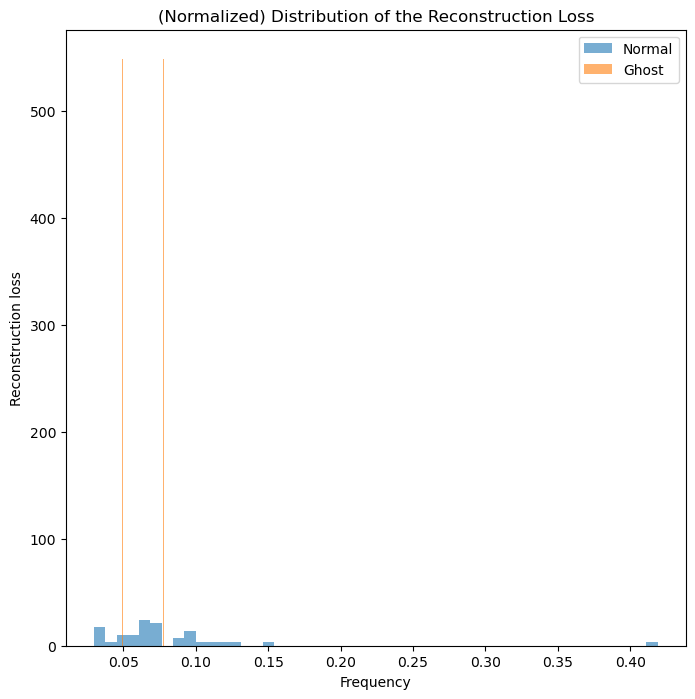

In [45]:
reconstruction_cae = cae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_cae, 2), axis=1)
plot_reconstruction_error(mse)

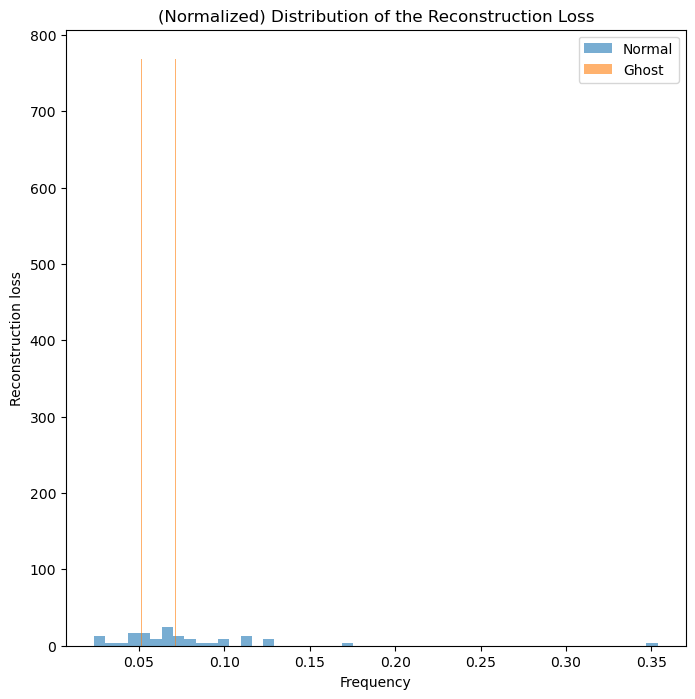

In [46]:
reconstruction_vae = vae.call(x_test)
mse = np.mean(np.power(x_test - reconstruction_vae, 2), axis=1)
plot_reconstruction_error(mse)

# ALAD
#### First we're gonna transfer the weights of the encoder part of the autoencoder to the generator of the ALAD

In [47]:
from models.ALAD import ALAD
from sklearn.metrics import accuracy_score


latent_dim = train_normal_data.shape[1]
alad = ALAD(input_dim=train_normal_data.shape[1], latent_dim=latent_dim, learning_rate=0.003)

# the model needs to be trained on the normal data to learn the underlying distribution
alad.train(train_normal_data, epochs=5, batch_size=64)

predictions = alad.predict(x_test)


# here we're relying on a threshold set just based on the percentile
threshold = alad.find_best_deviations_threshold(train_normal_data, x_test, y_test)


predictions = np.where(predictions > threshold, 1, 0)

#print the accuracy and the roc
accuracy = accuracy_score(y_test, predictions)
print('Accuracy of anomaly detection: {:.2f}%'.format(accuracy * 100))

Epoch: 1,  Encoder Loss: 6.942722320556641, Generator Loss: 6.689692974090576, Disc_xx Loss: 1.0287985801696777, Disc_xz Loss: 0.917539656162262, Disc_zz Loss: 2.842024803161621
Epoch: 2,  Encoder Loss: 10.57824420928955, Generator Loss: 10.276811599731445, Disc_xx Loss: 0.1308760941028595, Disc_xz Loss: 0.3817300796508789, Disc_zz Loss: 1.365604043006897
Epoch: 3,  Encoder Loss: 24.29058074951172, Generator Loss: 24.133323669433594, Disc_xx Loss: 0.006947141140699387, Disc_xz Loss: 0.16611921787261963, Disc_zz Loss: 1.1588246822357178
Epoch: 4,  Encoder Loss: 39.22597122192383, Generator Loss: 39.14472961425781, Disc_xx Loss: 0.0013618546072393656, Disc_xz Loss: 0.0847228541970253, Disc_zz Loss: 0.7622296810150146
Epoch: 5,  Encoder Loss: 32.850128173828125, Generator Loss: 32.79670715332031, Disc_xx Loss: 0.213984876871109, Disc_xz Loss: 0.06152302026748657, Disc_zz Loss: 0.201015904545784
Accuracy of anomaly detection: 7.50%


Accuracy: 0.0750
Precision: 0.0750
Recall: 1.0000
F1-Score: 0.1395
Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        37
           1       0.07      1.00      0.14         3

    accuracy                           0.07        40
   macro avg       0.04      0.50      0.07        40
weighted avg       0.01      0.07      0.01        40

the j_statistic is 0.0


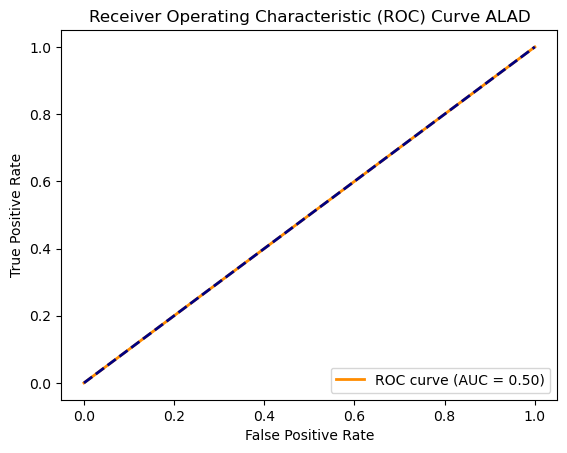

In [48]:
alad.classification_metrics(y_test, predictions, printing=True)
plot_ROC(y_test=y_test, predictions=predictions, name="ALAD")

# Isolation forest

Precision: 0.075
Recall: 1.0
F1-score: 0.13953488372093023
ROC AUC: 0.1171171171171171
the j_statistic is 0.0


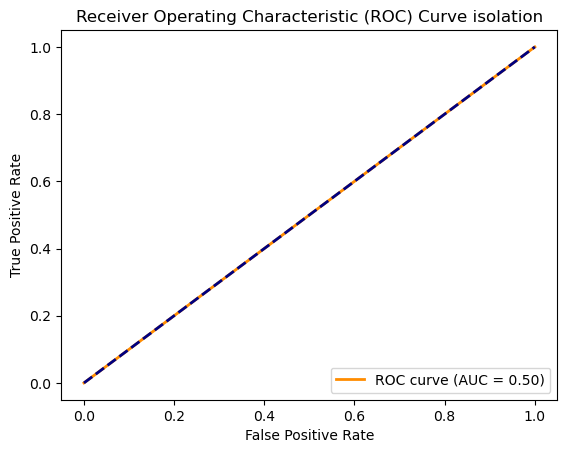

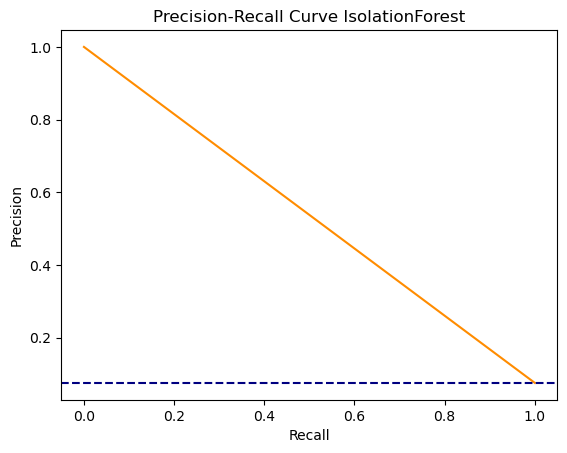

In [49]:
#this is an unsupervised learning method,
#in fact it is fed both normal and anomalous data
#during the training phase it learns from both normal and anomalous

from sklearn.ensemble import IsolationForest

X = df.drop(target_feature, axis=1)
y = df[target_feature]

X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, test_size=0.2, random_state=42)


x_train = (X_train - X_train.mean()) / X_train.std()
x_test = (x_test - X_train.mean()) / X_train.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

# trainig phase
clf = IsolationForest(n_estimators=10000, max_samples='auto', contamination=0.2, random_state=42)
clf.fit(x_train)

anomaly_scores = clf.decision_function(x_test)


y_pred = clf.predict(x_test)
y_pred = [1 if pred == -1 else 0 for pred in y_pred]



from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, anomaly_scores)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC AUC:", roc_auc)


plot_ROC(y_test, y_pred, "isolation")
pr_curve(y_test, y_pred, name="IsolationForest")

# One-class SVM

the j_statistic is 0.10810810810810811


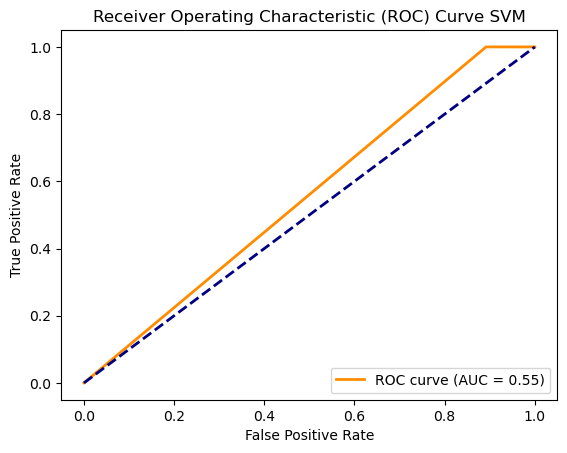

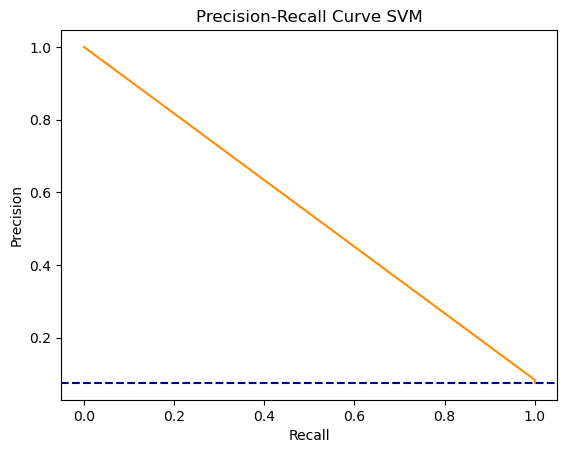

In [50]:

from sklearn import svm

# train the one class support vector machine
# nu specifies the upper bound on the tracks to be 
# classified as anomalies, it's a percentage 
# gamma controls the "smoothness" of the decision curve
# smaller gamma implies less overfitting but also lack of complexity...
clf = svm.OneClassSVM(nu=0.1, kernel="rbf", gamma=0.9)
clf.fit(train_normal_data)

# predict if the test instaces are anomalies or not
#Returns -1 for outliers and 1 for inliers.
y_pred = clf.predict(x_test)  


y_pred = [1 if pred == -1 else 0 for pred in y_pred]


# find the ROC curve 
plot_ROC(y_test, y_pred, "SVM")
pr_curve(y_test, y_pred, name="SVM")


# Ensemble classifier

Given none of the above methods has shown high performance, the last chance is to have them combined.

the j_statistic is 0.16216216216216217


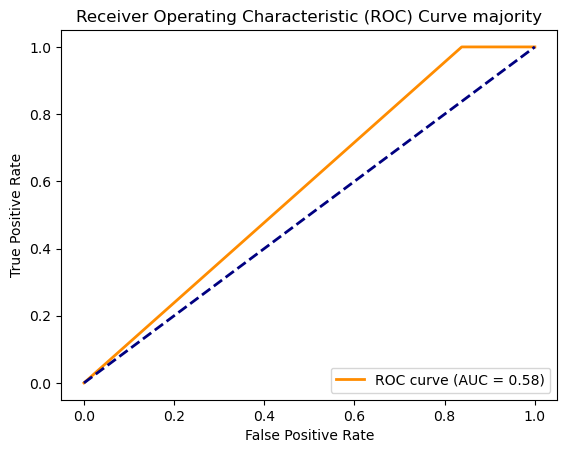

In [54]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression



#predictions_ae + predictions_cae +  predictions_vae

#Majority voting
final_array = np.where((predictions_ae + predictions_cae + predictions_vae) >= 2, 1, 0)

"""
#stacking classifiers
estimators = [
     ('ae', ae),
     ('cae', cae)]

clf = StackingClassifier(
     estimators=estimators, final_estimator=LogisticRegression()
)
clf.fit(train_normal_data, y_train).score(X_test, y_test)"""

plot_ROC(y_test=y_test, predictions=final_array, name="majority")

[0.34351145 0.32824427 0.32824427]
the j_statistic is 0.16216216216216217


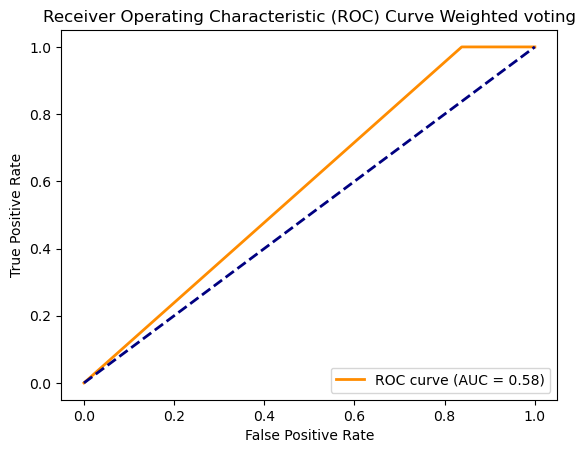

In [59]:
model_predictions = [predictions_ae, predictions_cae, predictions_vae]

auc_ae= roc_auc_score(y_test, predictions_ae)
auc_cae= roc_auc_score(y_test, predictions_cae)
auc_vae= roc_auc_score(y_test, predictions_vae)

weights = [auc_ae, auc_cae, auc_vae]

weights /= np.sum(weights)
final_prediction = np.average(model_predictions, axis=0, weights=weights)

#if a value is bigger then 0.5 the model will predict an anomaly 
final_prediction = np.round(final_prediction).astype(int)

plot_ROC(y_test=y_test, predictions=final_prediction, name="Weighted voting")